
<font color="#6E6E6E"><h2 align="left">Anomalías con Regresión/Reconstrucción</h2></font>

#### Valero Laparra


## Regresión

In [52]:
import numpy as np
import matplotlib.pyplot as plt

N = 1000

# Valores originales
x = np.random.rand(N,1)

#Valores predichos (fake)
y = x + 0.1*np.random.randn(x.shape[0],x.shape[1])
y[0] = y[0]*2.5

Text(0, 0.5, 'Y')

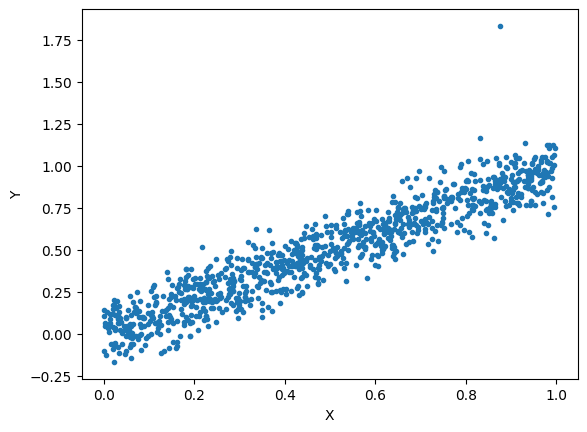

In [53]:
plt.plot(x,y,'.')
plt.xlabel('X')
plt.ylabel('Y')

EJERCICIO: Detecta la anomalia calculando el error de una regresion lineal.


In [54]:
from sklearn import linear_model

model = linear_model.LinearRegression()

In [55]:
model.fit(x,y)

LinearRegression()

In [56]:
y_hat = model.predict(x)

Text(0, 0.5, 'Y')

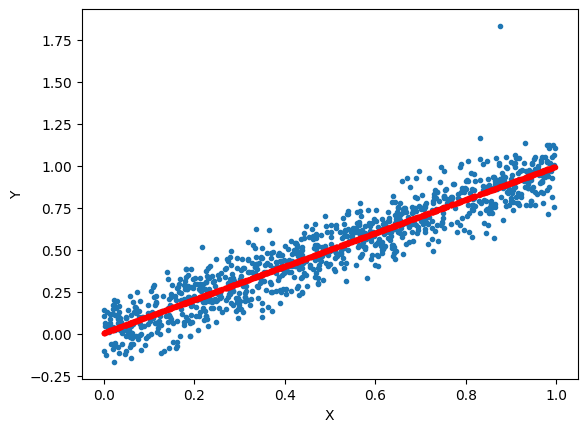

In [57]:
plt.plot(x,y,'.')
plt.plot(x,y_hat,'r.')

plt.xlabel('X')
plt.ylabel('Y')

Text(0, 0.5, 'Y')

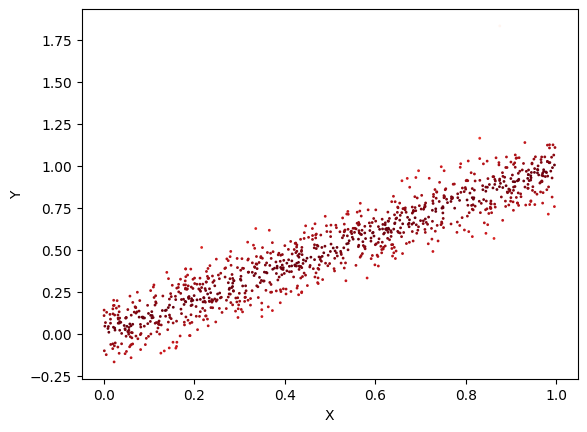

In [65]:
Err = np.abs(y-y_hat)
Anom = Err

plt.scatter(x,y, s=1, c=-Anom, cmap='Reds')
plt.xlabel('X')
plt.ylabel('Y')


Text(0, 0.5, 'Y')

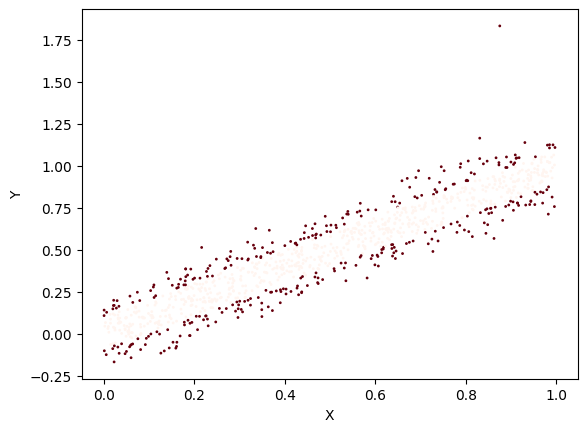

In [59]:
Anom = Err>0.1

plt.scatter(x,y, s=1, c=Anom, cmap='Reds')
plt.xlabel('X')
plt.ylabel('Y')

Text(0.5, 0, 'Error')

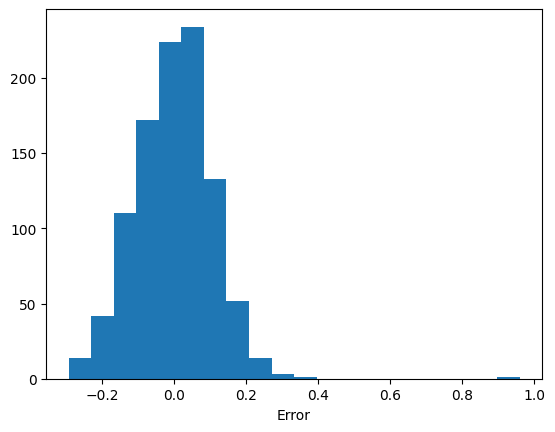

In [60]:
plt.hist(y-y_hat,bins=20)
plt.xlabel('Error')

Text(0, 0.5, 'Y')

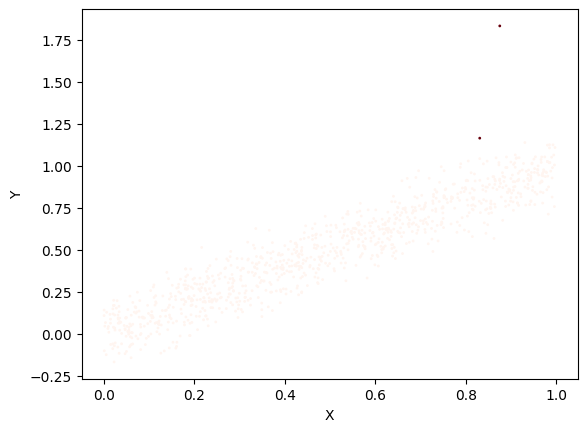

In [61]:

th = 3*np.std(y-y_hat)
Anom = Err>th

plt.scatter(x,y, s=1, c=Anom, cmap='Reds')
plt.xlabel('X')
plt.ylabel('Y')

Text(0, 0.5, 'Y')

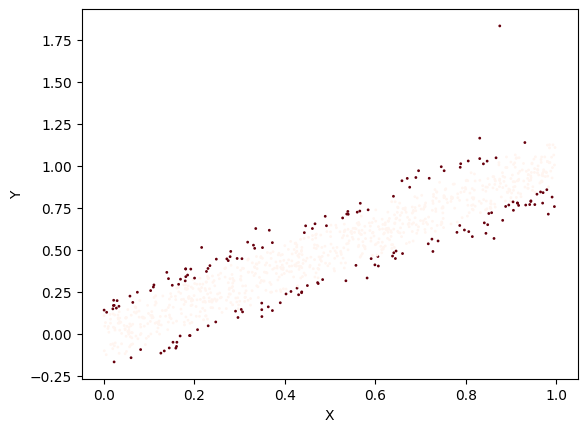

In [62]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)  # Conservamos los 2 primeros componentes principales

data = np.zeros((x.shape[0],2))
data[:,0] = x[:,0]
data[:,1] = y[:,0]
X_pca = pca.fit_transform(data)

Err = np.abs(X_pca[:,1])
Anom = Err>0.1

plt.scatter(x,y, s=1, c=Anom, cmap='Reds')
plt.xlabel('X')
plt.ylabel('Y')

Text(0, 0.5, 'Y')

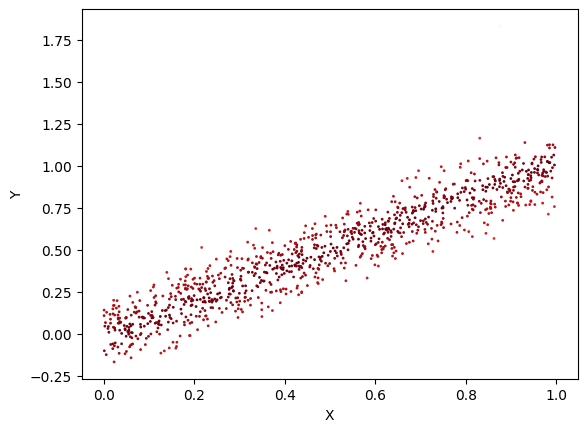

In [66]:
Err = np.abs(X_pca[:,1])
Anom = Err

plt.scatter(x,y, s=1, c=-Anom, cmap='Reds')
plt.xlabel('X')
plt.ylabel('Y')

EJERCICIO: Con los siguientes datos detecta las anomalías calculando el error de una regresion lineal. Haz lo mismo pero usando una regresión polinómica.


Text(0, 0.5, 'Y')

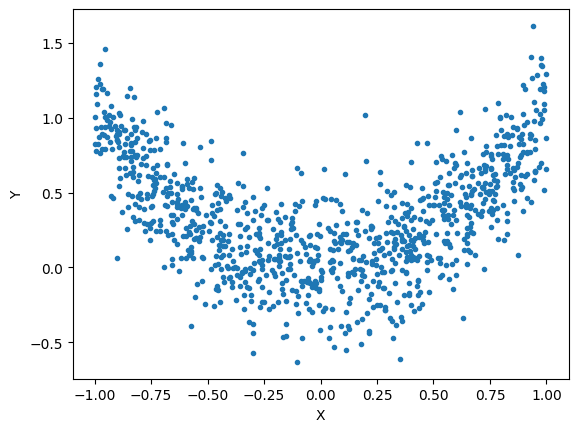

In [22]:
N = 1000

sigma = 0.25
# Valores originales
x = 2*((np.random.rand(N,1))-0.5)
y = x**2+ sigma*np.random.randn(y.shape[0],y.shape[1])
y[0] = y[0]+0.5
y[1] = y[1]-0.5

plt.plot(x,y,'.')
plt.xlabel('X')
plt.ylabel('Y')

In [23]:
from sklearn.preprocessing import PolynomialFeatures
poly = PolynomialFeatures(degree=2)  # Ajusta el grado del polinomio según sea necesario
X_train_poly = poly.fit_transform(x)

In [24]:
model2 = linear_model.LinearRegression()
model2.fit(X_train_poly,y)
y_hat2 = model2.predict(X_train_poly)
Err2 = np.abs(y-y_hat2)

Text(0, 0.5, 'Y')

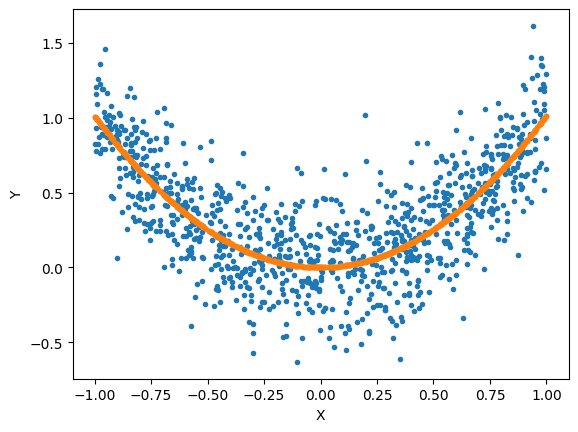

In [27]:
plt.plot(x,y,'.')
plt.plot(x,y_hat2,'.')
plt.xlabel('X')
plt.ylabel('Y')

Text(0, 0.5, 'Y')

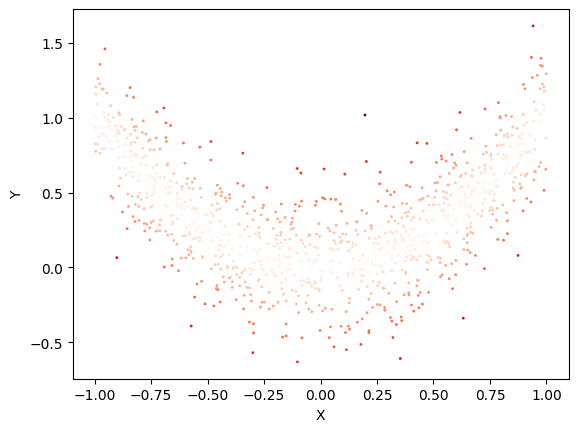

In [32]:
th = 3*np.std(y-y_hat2)
Anom = Err2

plt.scatter(x,y, s=1, c=Anom, cmap='Reds')
plt.xlabel('X')
plt.ylabel('Y')

Text(0, 0.5, 'Y')

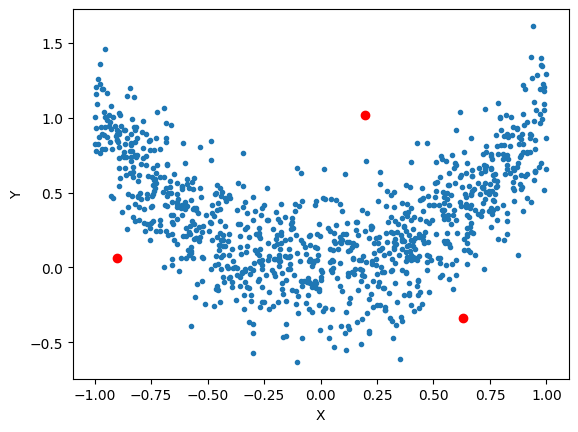

In [31]:
th = 3*np.std(y-y_hat2)
Anom = Err2>th

plt.plot(x,y,'.')
plt.plot(x[Anom,],y[Anom,],'ro')
plt.xlabel('X')
plt.ylabel('Y')

## Reconstrucción

EJERCICIO: Dados los siguientes datos calcula las anomalias quedándote con 1, 2, 3, o 4 dimensiones usando el PCA de sklearn.

In [33]:
from sklearn import datasets
import matplotlib.pyplot as plt
import numpy as np

iris = datasets.load_iris()
X = iris.data

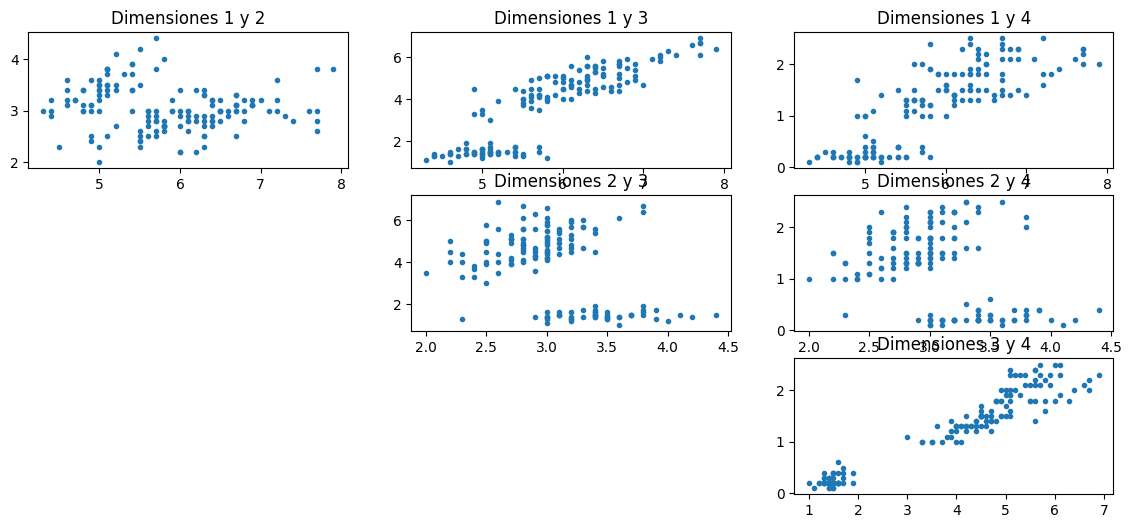

In [34]:
# Mostramos las combinaciones de dimensiones 2 a 2
plt.figure(figsize=(14,6))
plt.subplot(3,3,1), plt.plot(X[:,0],X[:,1],'.'), plt.title('Dimensiones 1 y 2')
plt.subplot(3,3,2), plt.plot(X[:,0],X[:,2],'.'), plt.title('Dimensiones 1 y 3')
plt.subplot(3,3,3), plt.plot(X[:,0],X[:,3],'.'), plt.title('Dimensiones 1 y 4')
plt.subplot(3,3,5), plt.plot(X[:,1],X[:,2],'.'), plt.title('Dimensiones 2 y 3')
plt.subplot(3,3,6), plt.plot(X[:,1],X[:,3],'.'), plt.title('Dimensiones 2 y 4')
plt.subplot(3,3,9), plt.plot(X[:,2],X[:,3],'.'), plt.title('Dimensiones 3 y 4');

In [36]:
from sklearn.decomposition import PCA

pca = PCA(n_components=4)  # Conservamos los 2 primeros componentes principales
X_pca = pca.fit_transform(X)

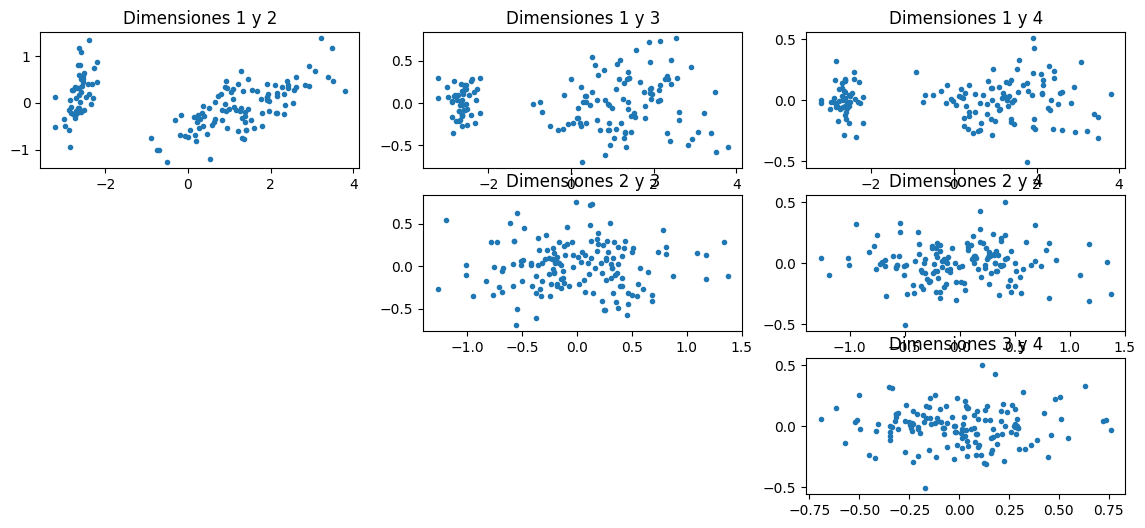

In [37]:
plt.figure(figsize=(14,6))
plt.subplot(3,3,1), plt.plot(X_pca[:,0],X_pca[:,1],'.'), plt.title('Dimensiones 1 y 2')
plt.subplot(3,3,2), plt.plot(X_pca[:,0],X_pca[:,2],'.'), plt.title('Dimensiones 1 y 3')
plt.subplot(3,3,3), plt.plot(X_pca[:,0],X_pca[:,3],'.'), plt.title('Dimensiones 1 y 4')
plt.subplot(3,3,5), plt.plot(X_pca[:,1],X_pca[:,2],'.'), plt.title('Dimensiones 2 y 3')
plt.subplot(3,3,6), plt.plot(X_pca[:,1],X_pca[:,3],'.'), plt.title('Dimensiones 2 y 4')
plt.subplot(3,3,9), plt.plot(X_pca[:,2],X_pca[:,3],'.'), plt.title('Dimensiones 3 y 4');

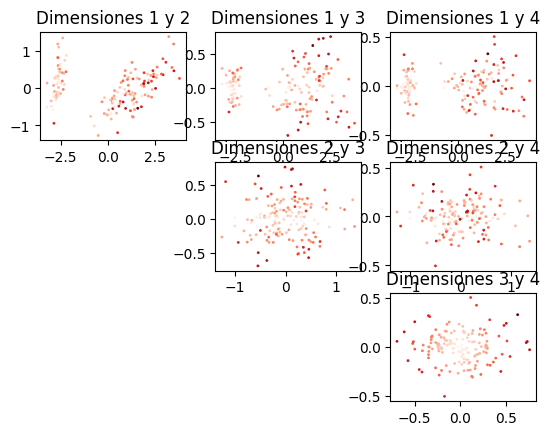

In [41]:
#A = np.abs(X-pca.inverse_transform(X_pca))
A = np.abs(X_pca[:,3]) + np.abs(X_pca[:,2])

plt.subplot(3,3,1), plt.scatter(X_pca[:,0],X_pca[:,1], s=1, c=A, cmap='Reds'), plt.title('Dimensiones 1 y 2')
plt.subplot(3,3,2), plt.scatter(X_pca[:,0],X_pca[:,2], s=1, c=A, cmap='Reds'), plt.title('Dimensiones 1 y 3')
plt.subplot(3,3,3), plt.scatter(X_pca[:,0],X_pca[:,3], s=1, c=A, cmap='Reds'), plt.title('Dimensiones 1 y 4')
plt.subplot(3,3,5), plt.scatter(X_pca[:,1],X_pca[:,2], s=1, c=A, cmap='Reds'), plt.title('Dimensiones 2 y 3')
plt.subplot(3,3,6), plt.scatter(X_pca[:,1],X_pca[:,3], s=1, c=A, cmap='Reds'), plt.title('Dimensiones 2 y 4')
plt.subplot(3,3,9), plt.scatter(X_pca[:,2],X_pca[:,3], s=1, c=A, cmap='Reds'), plt.title('Dimensiones 3 y 4');

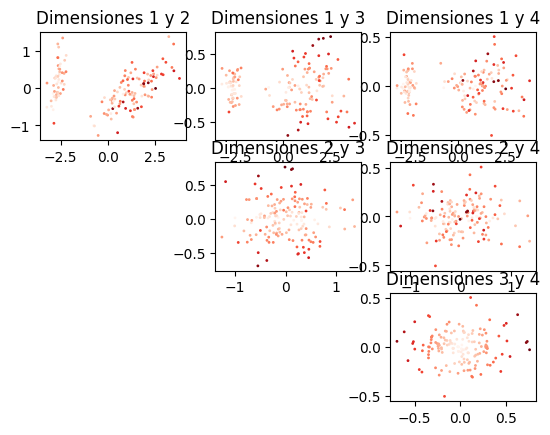

In [46]:
X_pca2 = np.zeros((X.shape[0],4))
X_pca2[:,0] = X_pca[:,0]
X_pca2[:,1] = X_pca[:,1]

A = np.sum(np.abs(X-pca.inverse_transform(X_pca2)),axis=1)
#A = np.abs(X_pca[:,3]) + np.abs(X_pca[:,2])

plt.subplot(3,3,1), plt.scatter(X_pca[:,0],X_pca[:,1], s=1, c=A, cmap='Reds'), plt.title('Dimensiones 1 y 2')
plt.subplot(3,3,2), plt.scatter(X_pca[:,0],X_pca[:,2], s=1, c=A, cmap='Reds'), plt.title('Dimensiones 1 y 3')
plt.subplot(3,3,3), plt.scatter(X_pca[:,0],X_pca[:,3], s=1, c=A, cmap='Reds'), plt.title('Dimensiones 1 y 4')
plt.subplot(3,3,5), plt.scatter(X_pca[:,1],X_pca[:,2], s=1, c=A, cmap='Reds'), plt.title('Dimensiones 2 y 3')
plt.subplot(3,3,6), plt.scatter(X_pca[:,1],X_pca[:,3], s=1, c=A, cmap='Reds'), plt.title('Dimensiones 2 y 4')
plt.subplot(3,3,9), plt.scatter(X_pca[:,2],X_pca[:,3], s=1, c=A, cmap='Reds'), plt.title('Dimensiones 3 y 4');

Text(0, 0.5, 'Y')

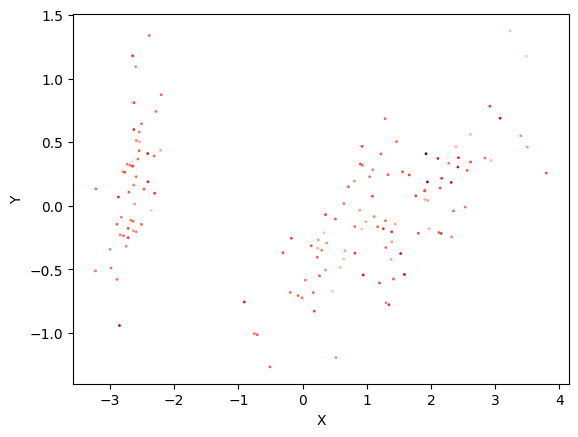

In [38]:


plt.scatter(X_pca[:,0],X_pca[:,1], s=1, c=A, cmap='Reds')
plt.xlabel('X')
plt.ylabel('Y')

## Datos a partir de una imagen

EJERCICIO: Con la siguiente imagen:

* Conviértela en datos de (D,N) tomando como dato patches de 8x8x3 y convirtiéndolos en vectores, es decir cada dato tiene dimensión D = 192.
* Calcula las anomalias usando PCA variando el número de dimensiones en la reconstrucción.

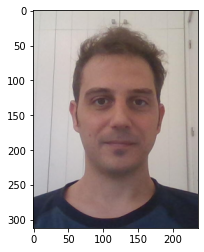

In [ ]:
# Hay muchas opciones para leer imagenes, openCV, PIL, sklearn...
import matplotlib.pyplot as plt
from skimage import io

im = io.imread('https://www.uv.es/lapeva/Valero_2020_DQ.png')

plt.imshow(im)

EJERCICIO: Mete un patch anómalo usando distintas estrategias en la imagen y analiza su distancia a los otros patches. Puedes probar las siguientes anomalías:  

* Pon el patch en negro (todos los valores a 0)
* Escala el valor del patch (multiplícalo por un valor un poco mas grande de 1).
* Cambia el contraste del patch.
* Mete ruido en el patch.